<a href="https://colab.research.google.com/github/fernandinhaalmeida84/Tech_Challenge_Fase_2/blob/main/Notebook/02_Defini%C3%A7%C3%A3o_Target.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Notebook 2: Definição do Target e Base de Modelagem**

## Onde estamos na história

No notebook 1 tratamos o cadastro e o histórico de crédito e fizemos a análise exploratória. Chegamos a duas bases limpas:

- **Cadastro** (`application_record_tratado`): uma linha por cliente, com o perfil de quem pediu o cartão.
- **Histórico** (`credit_record_tratado`): uma linha por cliente e mês, com o `STATUS` do pagamento daquele mês.

O problema de negócio é decidir, **na hora da concessão**, se um cliente vai ficar inadimplente. Para um modelo aprender isso, cada cliente precisa de uma resposta: *ficou inadimplente ou não?* Essa resposta é o **target**, e ele não existe pronto nas bases. Neste notebook nós o construímos.

## O que fazemos aqui

1. Juntamos as duas bases pelo `ID` (sem repetir a limpeza do notebook 1).
2. Definimos dois targets: **Inad90** (principal) e **Inad30** (alternativo).
3. Medimos o tamanho do histórico de cada cliente e mostramos por que **não** o usamos como variável.
4. Montamos a **base de modelagem**, que fica em memória: não criamos nenhum arquivo intermediário. Os notebooks seguintes partem das mesmas bases tratadas do notebook 1 e, quando precisarem desta junção, refazem o passo.

## 1. Configuração e leitura das bases

Lemos as duas bases tratadas direto da pasta `Data/`, com `pd.read_csv`. O código procura a pasta `Data/` a partir de onde o notebook está rodando; no Colab, se ela não existir, clonamos o repositório.

Fixamos o `RANDOM_STATE` desde já, para que qualquer ponto aleatório do projeto seja reproduzível.

In [1]:
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", None)

URL_REPO = "https://github.com/fernandinhaalmeida84/Tech_Challenge_Fase_2.git"


def localizar_data():
    """Acha a pasta Data/ (local ou clonada no Colab)."""
    for base in (Path.cwd(), Path.cwd().parent):
        for nome in ("Data", "data"):
            if (base / nome / "application_record_tratado.csv.gz").exists():
                return base / nome
    destino = Path("/content/Tech_Challenge_Fase_2")
    if not destino.exists():
        subprocess.run(["git", "clone", "--depth", "1", URL_REPO, str(destino)], check=True)
    return destino / "Data"


def br(n):
    """Formata inteiro com separador de milhar brasileiro."""
    return f"{int(n):,}".replace(",", ".")


def pct(x, casas=2):
    """Formata proporção como porcentagem brasileira."""
    return f"{x * 100:.{casas}f}%".replace(".", ",")


DATA_DIR = localizar_data()
ARQ_CADASTRO = DATA_DIR / "application_record_tratado.csv.gz"
ARQ_CREDITO = DATA_DIR / "credit_record_tratado.csv.gz"

# Definição dos targets: quais status contam como inadimplência
STATUS_INAD30 = ["1", "2", "3", "4", "5"]   # atraso a partir de 30 dias
STATUS_INAD90 = ["3", "4", "5"]             # atraso a partir de 90 dias

print("Pasta de dados:", DATA_DIR.name)

Pasta de dados: Data


In [2]:
cadastro = pd.read_csv(ARQ_CADASTRO)
credito = pd.read_csv(ARQ_CREDITO, dtype={"STATUS": str})

print(f"Cadastro: {br(cadastro.shape[0])} linhas x {cadastro.shape[1]} colunas")
print(f"Histórico: {br(credito.shape[0])} linhas x {credito.shape[1]} colunas")

Cadastro: 438.463 linhas x 22 colunas
Histórico: 1.048.575 linhas x 3 colunas


Antes de construir qualquer coisa, conferimos que as bases chegaram como esperávamos. Não refazemos a limpeza (ela é do notebook 1): só verificamos o que o target vai exigir, ou seja, **um cliente por linha no cadastro** e **um registro por cliente e mês no histórico**.

In [3]:
checagens = pd.DataFrame({
    "Verificação": [
        "Clientes no cadastro",
        "IDs únicos no cadastro",
        "Linhas no histórico",
        "Clientes distintos no histórico",
        "Linhas repetidas (mesmo ID e mesmo mês) no histórico",
        "Valores nulos no histórico",
    ],
    "Valor": [
        len(cadastro),
        cadastro["ID"].nunique(),
        len(credito),
        credito["ID"].nunique(),
        credito.duplicated(["ID", "MONTHS_BALANCE"]).sum(),
        credito.isna().sum().sum(),
    ],
})
checagens["Valor"] = checagens["Valor"].map(br)
display(checagens)

assert cadastro["ID"].is_unique, "Cadastro com ID repetido"
assert not credito.duplicated(["ID", "MONTHS_BALANCE"]).any(), "Histórico com mês repetido"

,Verificação,Valor
0,Clientes no cadastro,438.463
1,IDs únicos no cadastro,438.463
2,Linhas no histórico,1.048.575
3,Clientes distintos no histórico,45.985
4,Linhas repetidas (mesmo ID e mesmo mês) no histórico,0
5,Valores nulos no histórico,0


O cadastro tem um `ID` por cliente e o histórico não tem mês repetido, então a junção pelo `ID` não vai duplicar ninguém. Os IDs que antes apareciam repetidos no cadastro já foram removidos no notebook 1, e nenhum deles tinha histórico, logo não perdemos rótulo nenhum com essa remoção.

## 2. Como lemos o `STATUS`

O `STATUS` descreve a situação do cliente em cada mês. Nem todo status é problema, e é aqui que a definição do target começa a pesar:

- `C` (pago) e `X` (sem empréstimo no mês) são situações normais.
- `0` é um atraso curto, de 1 a 29 dias. É comum e frequentemente é só um esquecimento, então **não tratamos como inadimplência**.
- `1` e `2` (30 a 89 dias) são a **zona cinza**: o cliente já está atrasado, mas ainda não chegou ao ponto de ser considerado perda.
- `3`, `4` e `5` (90 dias ou mais, até baixa por perda) são inadimplência no sentido clássico de crédito.

In [4]:
significado = {
    "C": "Pago no mês",
    "X": "Sem empréstimo no mês",
    "0": "Atraso de 1 a 29 dias",
    "1": "Atraso de 30 a 59 dias",
    "2": "Atraso de 60 a 89 dias",
    "3": "Atraso de 90 a 119 dias",
    "4": "Atraso de 120 a 149 dias",
    "5": "Atraso acima de 150 dias / baixa",
}

contagem = credito["STATUS"].value_counts()
tabela_status = pd.DataFrame({
    "STATUS": list(significado),
    "Significado": list(significado.values()),
    "Linhas": [contagem.get(s, 0) for s in significado],
})
tabela_status["% das linhas"] = (tabela_status["Linhas"] / len(credito)).map(pct)
tabela_status["Conta no Inad30?"] = np.where(tabela_status["STATUS"].isin(STATUS_INAD30), "Sim", "Não")
tabela_status["Conta no Inad90?"] = np.where(tabela_status["STATUS"].isin(STATUS_INAD90), "Sim", "Não")
tabela_status["Linhas"] = tabela_status["Linhas"].map(br)
display(tabela_status)

,STATUS,Significado,Linhas,% das linhas,Conta no Inad30?,Conta no Inad90?
0,C,Pago no mês,442.031,"42,16%",Não,Não
1,X,Sem empréstimo no mês,209.230,"19,95%",Não,Não
2,0,Atraso de 1 a 29 dias,383.120,"36,54%",Não,Não
3,1,Atraso de 30 a 59 dias,11.090,"1,06%",Sim,Não
4,2,Atraso de 60 a 89 dias,868,"0,08%",Sim,Não
5,3,Atraso de 90 a 119 dias,320,"0,03%",Sim,Sim
6,4,Atraso de 120 a 149 dias,223,"0,02%",Sim,Sim
7,5,Atraso acima de 150 dias / baixa,1.693,"0,16%",Sim,Sim


### Decisão: dois targets, sem excluir a zona cinza

Definimos o target **no nível do cliente**, olhando todo o histórico dele: o cliente é marcado como inadimplente se **em algum mês** teve um status que cai na regra.

| Target | Regra | Papel |
|---|---|---|
| **Inad90** | status 3, 4 ou 5 em algum mês | **Principal.** É a definição usual de inadimplência: atraso a partir de 90 dias. |
| **Inad30** | status 1, 2, 3, 4 ou 5 em algum mês | **Alternativo.** Mais sensível: pega o cliente já nos primeiros sinais de atraso. |

Duas escolhas importantes:

- **Status `0` não é inadimplência.** Atrasos de até 29 dias são frequentes e, se os contássemos, o modelo passaria a prever "esquecimento", não risco de crédito.
- **Não excluímos a zona cinza (30 a 89 dias).** Poderíamos tirar da base os clientes que ficaram na zona cinza e nunca passaram de 90 dias, para deixar o Inad90 "mais limpo". Preferimos manter todos: assim o Inad90 trata esses clientes como bons pagadores (o que de fato são, pela definição de 90 dias) e a base continua representando a carteira real, sem um recorte artificial.

## 3. Construindo o target por cliente

Para cada `ID` olhamos todas as linhas do histórico e aplicamos a regra "em algum mês". Aproveitamos a mesma passada para medir o **tamanho do histórico** (quantos meses distintos o cliente tem registrados), que vamos analisar na seção 6.

In [5]:
marcas = credito.assign(
    ATRASO_30=credito["STATUS"].isin(STATUS_INAD30),
    ATRASO_90=credito["STATUS"].isin(STATUS_INAD90),
)

alvo = (
    marcas.groupby("ID")
    .agg(
        Inad90=("ATRASO_90", "max"),
        Inad30=("ATRASO_30", "max"),
        MESES_HISTORICO=("MONTHS_BALANCE", "nunique"),
    )
    .reset_index()
)
alvo[["Inad90", "Inad30"]] = alvo[["Inad90", "Inad30"]].astype(int)

print(f"Clientes com target calculado: {br(len(alvo))}")
display(alvo.head())

Clientes com target calculado: 45.985


,ID,Inad90,Inad30,MESES_HISTORICO
0,5001711,0,0,4
1,5001712,0,0,19
2,5001713,0,0,22
3,5001714,0,0,15
4,5001715,0,0,60


## 4. Juntando com o cadastro

Agora ligamos o target ao perfil do cliente pelo `ID`. Usamos junção **interna** (`inner`): ficam só os clientes que existem nas duas bases, porque:

- um cliente **sem histórico** não tem como ser rotulado (não sabemos se pagaria ou não), então não serve para treinar nem avaliar o modelo;
- um ID que está **só no histórico** não tem perfil, então não tem variável nenhuma para o modelo usar.

O `validate="one_to_one"` faz o pandas falhar se algum ID estiver duplicado em qualquer lado, o que protege a junção.

In [6]:
ids_cadastro = set(cadastro["ID"])
ids_historico = set(alvo["ID"])

base = cadastro.merge(alvo, on="ID", how="inner", validate="one_to_one")

funil = pd.DataFrame({
    "Etapa": [
        "Clientes no cadastro",
        "(-) Sem histórico de crédito, sem como rotular",
        "(=) Clientes com perfil e histórico (base de modelagem)",
        "Memo: IDs só no histórico, sem perfil, ignorados",
    ],
    "Clientes": [
        len(ids_cadastro),
        len(ids_cadastro - ids_historico),
        len(base),
        len(ids_historico - ids_cadastro),
    ],
})
funil["% do cadastro"] = (funil["Clientes"] / len(ids_cadastro)).map(pct)
funil.loc[3, "% do cadastro"] = "-"
funil["Clientes"] = funil["Clientes"].map(br)
display(funil)

assert len(base) == len(ids_cadastro & ids_historico)

,Etapa,Clientes,% do cadastro
0,Clientes no cadastro,438.463,"100,00%"
1,"(-) Sem histórico de crédito, sem como rotular",402.006,"91,69%"
2,(=) Clientes com perfil e histórico (base de modelagem),36.457,"8,31%"
3,"Memo: IDs só no histórico, sem perfil, ignorados",9.528,-


Isso vale ser dito na história: **só uma pequena parte do cadastro (cerca de 8%) tem histórico de crédito**, e é apenas nela que conseguimos medir inadimplência. É uma limitação da base, não uma escolha nossa, e vamos lembrar dela nas conclusões: o modelo aprende com quem teve cartão acompanhado.

## 5. Como ficaram os targets

Olhamos três coisas: quantos clientes caem em cada target, se os dois são coerentes entre si e quanto pesa a zona cinza.

In [7]:
resumo_alvos = pd.DataFrame({
    "Target": ["Inad90 (principal)", "Inad30 (alternativo)"],
    "Inadimplentes": [base["Inad90"].sum(), base["Inad30"].sum()],
    "Total de clientes": [len(base), len(base)],
})
resumo_alvos["Taxa de inadimplência"] = (resumo_alvos["Inadimplentes"] / resumo_alvos["Total de clientes"]).map(pct)
resumo_alvos["Inadimplentes"] = resumo_alvos["Inadimplentes"].map(br)
resumo_alvos["Total de clientes"] = resumo_alvos["Total de clientes"].map(br)
display(resumo_alvos)

# Coerência: quem é Inad90 tem que ser Inad30 (a regra de 90 dias está contida na de 30)
assert (base["Inad90"] <= base["Inad30"]).all(), "Inad90 não pode existir sem Inad30"

cruzamento = pd.crosstab(
    base["Inad30"].map({0: "Inad30 = 0", 1: "Inad30 = 1"}),
    base["Inad90"].map({0: "Inad90 = 0", 1: "Inad90 = 1"}),
)
display(cruzamento)

,Target,Inadimplentes,Total de clientes,Taxa de inadimplência
0,Inad90 (principal),302,36.457,"0,83%"
1,Inad30 (alternativo),4.291,36.457,"11,77%"


Inad90,Inad90 = 0,Inad90 = 1
Inad30,,
Inad30 = 0,32166,0
Inad30 = 1,3989,302


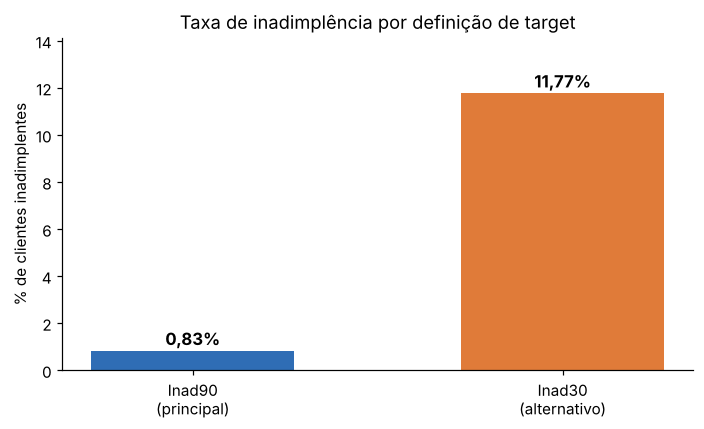

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4))
taxas = [base["Inad90"].mean(), base["Inad30"].mean()]
barras = ax.bar(["Inad90\n(principal)", "Inad30\n(alternativo)"], [t * 100 for t in taxas],
                color=["#2F6DB5", "#E07B39"], width=0.55)
for barra, t in zip(barras, taxas):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.25, pct(t),
            ha="center", fontsize=11, fontweight="bold")
ax.set_ylabel("% de clientes inadimplentes")
ax.set_title("Taxa de inadimplência por definição de target")
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, max(taxas) * 100 * 1.2)
plt.tight_layout()
plt.show()

In [9]:
so_30 = int(((base["Inad30"] == 1) & (base["Inad90"] == 0)).sum())
print(f"Zona cinza (Inad30 = 1 e Inad90 = 0): {br(so_30)} clientes ({pct(so_30 / len(base))} da base)")
print(f"Inad90 = 1: {br(base['Inad90'].sum())} clientes ({pct(base['Inad90'].mean())} da base)")
print(f"Proporção de Inad90 entre os Inad30: {pct(base['Inad90'].sum() / base['Inad30'].sum(), 1)}")

Zona cinza (Inad30 = 1 e Inad90 = 0): 3.989 clientes (10,94% da base)
Inad90 = 1: 302 clientes (0,83% da base)
Proporção de Inad90 entre os Inad30: 7,0%


**O que isso nos diz:**

- **O Inad90 é raro.** Pouco mais de 300 clientes em mais de 36 mil. Isso é coerente com o negócio (quem chega a 90 dias de atraso é exceção), mas tem consequência direta para a modelagem: com uma classe tão pequena, **acurácia não serve como métrica** (um modelo que sempre responde "bom pagador" acertaria mais de 99% e não serviria para nada). No notebook 3 vamos precisar de métricas que olhem a classe rara (recall, precisão, F1, AUC-ROC e curva precisão-recall) e de tratamento do desbalanceamento.
- **O Inad30 é cerca de 14 vezes mais frequente** e pega os atrasos mais cedo. Por isso o mantemos como alternativo: ele dá ao modelo muito mais exemplos de "problema" para aprender, ao custo de misturar atrasos leves com graves.
- **A zona cinza é grande** (quase 11% da base) e é exatamente o que separa os dois targets. Como decidimos não excluí-la, esses clientes seguem na base e contam como bons pagadores no Inad90 e como inadimplentes no Inad30.
- A checagem de coerência passou: ninguém é Inad90 sem ser Inad30, como a regra exige.

## 6. O tamanho do histórico e por que não o usamos como variável

`MESES_HISTORICO` conta quantos meses o cliente tem registrados. Parece uma variável útil, mas ela esconde duas armadilhas:

1. **Só existe depois da aprovação.** Na hora de decidir se o crédito sai, o cliente ainda não tem histórico nenhum. Usar essa informação para prever o resultado seria dar ao modelo algo que ele não teria na vida real (vazamento de informação).
2. **Está ligada ao próprio target.** Quanto mais meses de observação, mais chances o cliente teve de atrasar. Um cliente com 6 meses de histórico ainda "não teve tempo" de ficar inadimplente.

Primeiro medimos o tamanho do histórico; depois mostramos a segunda armadilha nos dados.

,count,mean,std,min,25%,50%,75%,max
MESES_HISTORICO,36457.0,21.3,14.9,1.0,9.0,18.0,31.0,61.0


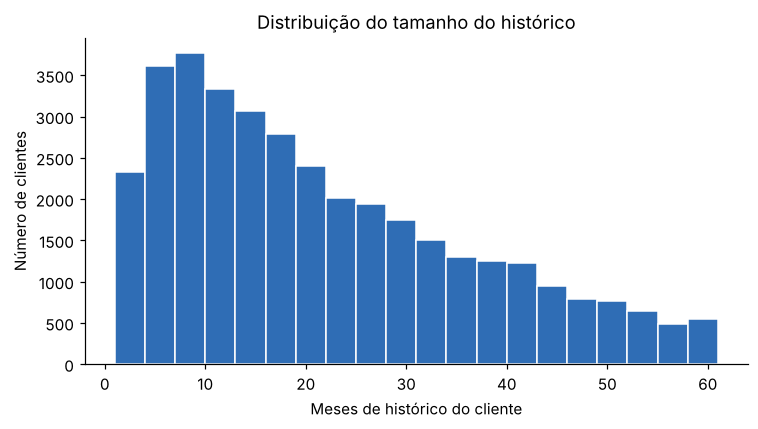

In [10]:
display(base["MESES_HISTORICO"].describe().round(1).to_frame("MESES_HISTORICO").T)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(base["MESES_HISTORICO"], bins=range(1, 63, 3), color="#2F6DB5", edgecolor="white")
ax.set_xlabel("Meses de histórico do cliente")
ax.set_ylabel("Número de clientes")
ax.set_title("Distribuição do tamanho do histórico")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

,Clientes,Taxa_Inad90,Taxa_Inad30
MESES_HISTORICO,,,
1 a 6,5.944,"0,15%","4,00%"
7 a 12,7.094,"0,28%","10,54%"
13 a 24,10.266,"0,64%","13,08%"
25 a 36,6.502,"0,80%","13,35%"
37 a 61,6.651,"2,33%","16,45%"


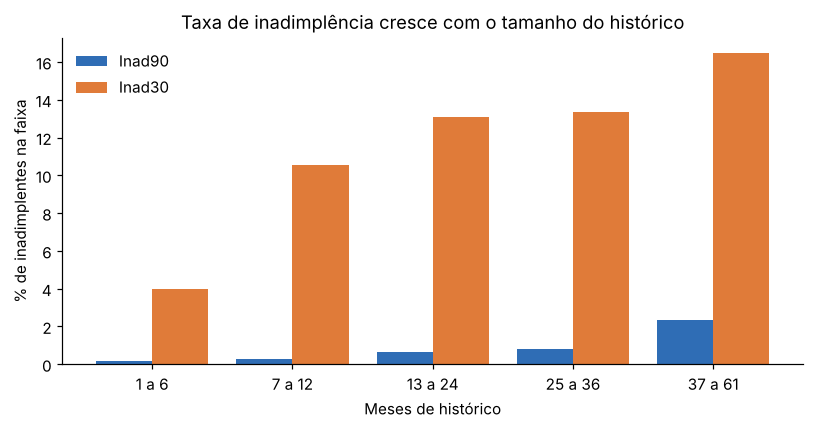

In [11]:
faixas = pd.cut(
    base["MESES_HISTORICO"],
    bins=[0, 6, 12, 24, 36, 61],
    labels=["1 a 6", "7 a 12", "13 a 24", "25 a 36", "37 a 61"],
)
por_faixa = (
    base.groupby(faixas, observed=True)
    .agg(Clientes=("ID", "size"), Taxa_Inad90=("Inad90", "mean"), Taxa_Inad30=("Inad30", "mean"))
)

fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(len(por_faixa))
ax.bar(x - 0.2, por_faixa["Taxa_Inad90"] * 100, width=0.4, label="Inad90", color="#2F6DB5")
ax.bar(x + 0.2, por_faixa["Taxa_Inad30"] * 100, width=0.4, label="Inad30", color="#E07B39")
ax.set_xticks(x)
ax.set_xticklabels(por_faixa.index)
ax.set_xlabel("Meses de histórico")
ax.set_ylabel("% de inadimplentes na faixa")
ax.set_title("Taxa de inadimplência cresce com o tamanho do histórico")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

tabela_faixa = por_faixa.copy()
tabela_faixa["Clientes"] = tabela_faixa["Clientes"].map(br)
tabela_faixa["Taxa_Inad90"] = tabela_faixa["Taxa_Inad90"].map(pct)
tabela_faixa["Taxa_Inad30"] = tabela_faixa["Taxa_Inad30"].map(pct)
display(tabela_faixa)

**Leitura:** a taxa de inadimplência sobe junto com o tamanho do histórico, nos dois targets. Isso confirma o efeito de **tempo de exposição**: parte da diferença entre clientes "bons" e "maus" é só quantos meses cada um foi observado, e não quem eles são.

Por isso tomamos duas decisões:

- `MESES_HISTORICO` **não entra como variável do modelo**. Fica na base apenas como coluna de **auditoria**, para podermos refazer esta análise e interpretar os resultados.
- Registramos como **limitação**: clientes com histórico curto podem estar classificados como "bons" simplesmente porque ainda não tiveram tempo de atrasar.

## 7. Montando a base de modelagem

Reorganizamos as colunas em grupos, para que o notebook 3 saiba exatamente o que é o quê:

- **Identificação:** `ID` e `PERFIL_ID`. O `PERFIL_ID` agrupa clientes com as mesmas características; vamos usá-lo no notebook 3 para que clientes de mesmo perfil não fiquem uns no treino e outros no teste.
- **Variáveis do cliente:** tudo o que o cadastro informa (inclui `Idade`, `Desempregado ou aposentado` e `Anos_Trabalhados`, criadas no notebook 1).
- **Targets:** `Inad90` (principal) e `Inad30` (alternativo).
- **Auditoria:** `MESES_HISTORICO`, que **não é variável do modelo**.

In [12]:
ID_COLS = ["ID", "PERFIL_ID"]
TARGET_COLS = ["Inad90", "Inad30"]
AUDITORIA_COLS = ["MESES_HISTORICO"]
FEATURE_COLS = [c for c in cadastro.columns if c not in ID_COLS]

base_modelagem = base[ID_COLS + FEATURE_COLS + TARGET_COLS + AUDITORIA_COLS].copy()

print(f"Base de modelagem: {br(base_modelagem.shape[0])} clientes x {base_modelagem.shape[1]} colunas")
print(f"Variáveis do cliente disponíveis para o modelo: {len(FEATURE_COLS)}")

# Checagens finais antes de salvar
assert base_modelagem["ID"].is_unique
assert base_modelagem.isna().sum().sum() == 0, "A base não pode ter nulos"
assert set(base_modelagem["Inad90"].unique()) <= {0, 1}
assert set(base_modelagem["Inad30"].unique()) <= {0, 1}
assert (base_modelagem["Inad90"] <= base_modelagem["Inad30"]).all()
print("Checagens finais: ok (ID único, sem nulos, targets binários e coerentes).")

display(base_modelagem.head())

Base de modelagem: 36.457 clientes x 25 colunas
Variáveis do cliente disponíveis para o modelo: 20
Checagens finais: ok (ID único, sem nulos, targets binários e coerentes).


,ID,PERFIL_ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,Idade,Desempregado ou aposentado,Anos_Trabalhados,Inad90,Inad30,MESES_HISTORICO
0,5008804,85107,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,Unknown,2.0,32.867899,False,12.435318,0,1,16
1,5008805,85107,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,Unknown,2.0,32.867899,False,12.435318,0,1,15
2,5008806,78469,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0,58.792608,False,3.104723,0,0,30
3,5008808,34268,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0,52.320329,False,8.353183,0,0,5
4,5008809,34268,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0,52.320329,False,8.353183,0,0,5


In [13]:
dicionario = pd.DataFrame({
    "Coluna": base_modelagem.columns,
    "Tipo": base_modelagem.dtypes.astype(str).values,
    "Papel": (
        ["Identificação"] * len(ID_COLS)
        + ["Variável do cliente"] * len(FEATURE_COLS)
        + ["Target"] * len(TARGET_COLS)
        + ["Auditoria (não usar no modelo)"] * len(AUDITORIA_COLS)
    ),
})
# a ordem acima segue a ordem das colunas de base_modelagem
display(dicionario)

,Coluna,Tipo,Papel
0,ID,int64,Identificação
1,PERFIL_ID,int64,Identificação
2,CODE_GENDER,str,Variável do cliente
3,FLAG_OWN_CAR,str,Variável do cliente
4,FLAG_OWN_REALTY,str,Variável do cliente
5,CNT_CHILDREN,int64,Variável do cliente
6,AMT_INCOME_TOTAL,float64,Variável do cliente
7,NAME_INCOME_TYPE,str,Variável do cliente
8,NAME_EDUCATION_TYPE,str,Variável do cliente
9,NAME_FAMILY_STATUS,str,Variável do cliente


## 8. Por que não salvamos a base

Decidimos **não gravar a base de modelagem em arquivo**. As entradas continuam sendo as duas bases tratadas do notebook 1, e tudo o que fizemos aqui (junção, targets, histórico) roda em poucos segundos. Se o notebook 3 precisar da mesma junção, ele a refaz, mesmo que isso repita código. Assim evitamos arquivos intermediários que poderiam ficar desatualizados em relação à regra do target e mantemos cada notebook executável sozinho, a partir das bases tratadas.

Antes de fechar, conferimos o que fica na memória e o que o notebook 3 precisa descartar para não vazar informação.

In [14]:
descartar_no_modelo = ID_COLS + TARGET_COLS + AUDITORIA_COLS
usar_no_modelo = [c for c in base_modelagem.columns if c not in descartar_no_modelo]

print(f"Base de modelagem em memória: {br(base_modelagem.shape[0])} clientes x {base_modelagem.shape[1]} colunas")
print(f"Colunas a descartar na modelagem: {descartar_no_modelo}")
print(f"Variáveis candidatas a entrar no modelo: {len(usar_no_modelo)}")

Base de modelagem em memória: 36.457 clientes x 25 colunas
Colunas a descartar na modelagem: ['ID', 'PERFIL_ID', 'Inad90', 'Inad30', 'MESES_HISTORICO']
Variáveis candidatas a entrar no modelo: 20


## 9. Resumo e próximo passo

**O que fizemos**

- Juntamos cadastro e histórico pelo `ID` e ficamos com os clientes que têm perfil **e** histórico, a única parte da base em que conseguimos medir inadimplência.
- Criamos o **Inad90** (principal: status 3, 4 ou 5 em algum mês) e o **Inad30** (alternativo: status 1 a 5). Status `0` não conta, e a zona cinza ficou na base.
- Medimos o histórico (`MESES_HISTORICO`) e mostramos que ele cresce junto com a inadimplência; por isso fica como coluna de auditoria e **não** como variável.
- Montamos a **base de modelagem**, validada (ID único, sem nulos, targets coerentes), sem criar arquivos novos.

**O que levamos para o notebook 3**

- O Inad90 é uma classe **rara**: acurácia não serve, e precisamos de métricas e de tratamento voltados à classe minoritária.
- O notebook 3 parte das bases tratadas do notebook 1 e **refaz a junção e os targets** (seções 3 a 5 deste notebook). Para evitar vazamento, deve **descartar** `ID`, os targets e `MESES_HISTORICO`, e usar o `PERFIL_ID` para dividir treino e teste por grupo.
- O Inad30 fica disponível como alvo alternativo, para comparar o quanto a definição do target muda a capacidade do modelo.